Calculating continued fractions for various constants with N =  20
sqrt(2) =  1.414213562373095
phi =  1.618033985017358
e =  2.718281828459045
silver ratio =  2.414213562373095
ln(2) =  0.6931471805599454
Calculating continued fractions for various functions with x =  0.5 and N =  20
exp(x) = 1.6487212707001282
tanh(x) =  0.46211715726000974
arctan(x) =  0.4636476090008061
tan(x) =  0.5463024898437905
sqrt(1+x) =  1.224744871391589
Name            Approximation        Reference            Absolute Error       Relative Error
---------------------------------------------------------------------------------------------------------
sqrt(2)         1.414213562373       1.414213562373       2.220e-16            1.570e-16
phi             1.618033985017       1.618033988750       3.733e-09            2.307e-09
e               2.718281828459       2.718281828459       0.000e+00            0.000e+00
silver ratio    2.414213562373       1.618033988750       7.962e-01            4.921e-01
ln(2)  

C:\Users\samst\AppData\Local\Temp\ipykernel_17784\1580312207.py:165: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


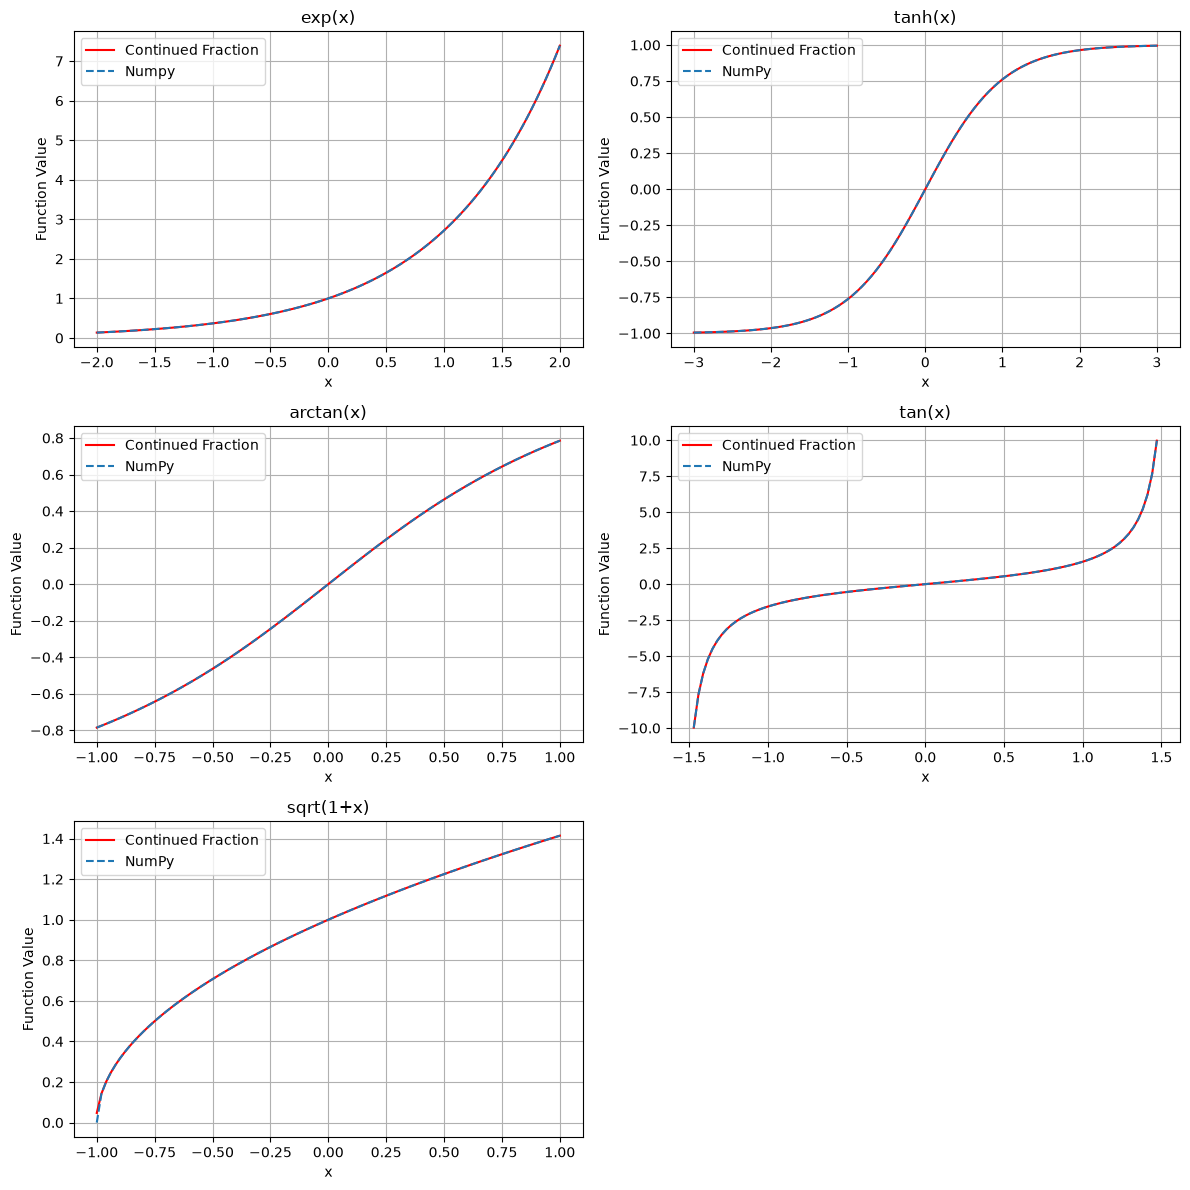

In [8]:
import numpy as np
import matplotlib.pyplot as plt

#This is the general continued fraction evaluator
def continued_fraction(a, b, N):
    x = a(N)
    for n in range(N - 1, -1, -1):
        x = a(n) + b(n+1) / x
    return x

#The five constants with contiuned fraction formulas

#sqrt(2)
def a_sqrt2(n):
    return 1 if n == 0 else 2
def b_sqrt2(n):
    return 1

#Golden Ratio
def a_phi(n):
    return 1
def b_phi(n):
    return 1

#Euler's Number
def a_e(n):
    if n == 0:
        return 2
    elif n % 3 == 2:
        return 2 * (n // 3+1)
    else:
        return 1
def b_e(n):
    return 1

#Silver Ratio
def a_silver(n):
    return 2
def b_silver(n):
    return 1

#ln(2)
def a_ln2(n):
    return n+1
def b_ln2(n):
    return ((n+1) // 2) ** 2

#Printing the continued fractions for the constants
N = 20
print("Calculating continued fractions for various constants with N = ", N)
print("sqrt(2) = ", continued_fraction(a_sqrt2, b_sqrt2, N))
print("phi = ", continued_fraction(a_phi, b_phi, N))
print("e = ", continued_fraction(a_e, b_e, N))
print("silver ratio = ", continued_fraction(a_silver, b_silver, N))
print("ln(2) = ", 1 / continued_fraction(a_ln2, b_ln2, N))
#The five functions with contiued fraction formulas

#exponential function
def exf(x, N):
    def a(n):
        if n == 0:
            return 1
        elif n == 1:
            return 2-x
        else:
            return 4*n - 2
    def b(n):
        if n == 1:
            return 2*x
        else:
            return x**2
    return continued_fraction(a, b, N)

#hyperbolic tangent function
def tanhf(x, N):
    def a(n):
        return 1 if n == 0 else 2*n +1
    def b(n):
        return x**2
    return x / continued_fraction(a, b, N)

#arctangent function
def arctanf(x, N):
    def a(n):
        return 1 if n == 0 else 2*n +1
    def b(n):
        return (n*x) ** 2
    return x / continued_fraction(a, b, N)

#tangent function
def tanf(x, N):
    def a(n):
        return 1 if n == 0 else 2*n +1
    def b(n):
        return -x**2
    return x / continued_fraction(a, b, N)

#square root of 1+x function
def sqrtf(x, N):
    def a(n):
        return 1 if n == 0 else 2
    def b(n):
        return x
    return continued_fraction(a, b, N)
x = 0.5

#printing the continued fractions for the functions
print("Calculating continued fractions for various functions with x = ", x, "and N = ", N)
print("exp(x) =", exf(x, N))
print("tanh(x) = ", tanhf(x, N))
print("arctan(x) = ", arctanf(x, N))
print("tan(x) = ", tanf(x, N))
print("sqrt(1+x) = ", sqrtf(x, N))

#comparing each constant with a reference value from Numpy and printing the absolute and relative errors
constants = [
    ("sqrt(2)", continued_fraction(a_sqrt2, b_sqrt2, N), np.sqrt(2)),
    ("phi", continued_fraction(a_phi, b_phi, N), (1+np.sqrt(5))/2),
    ("e", continued_fraction(a_e, b_e, N), np.e),
    ("silver ratio", continued_fraction(a_silver, b_silver, N), (1+np.sqrt(5))/2),
    ("ln(2)", 1 / continued_fraction(a_ln2, b_ln2, N), np.log(2))
]
def print_table(rows):
    print(f"{'Name':<15} {'Approximation':<20} {'Reference':<20} {'Absolute Error':<20} {'Relative Error'}")
    print("-" * 105)
    for name, approx, ref in rows:
        error = abs(approx - ref)
        print(f"{name:<15} {approx:<20.12f} {ref:<20.12f} {error:<20.3e} {error / abs(ref):.3e}")
print_table(constants)

#Plotting the functions and their continued fraction approximations
x_exf = np.linspace(-2,2,100)
x_tanhf = np.linspace(-3,3,100)
x_arctanf = np.linspace(-1,1,100)
x_tanf = np.linspace(-np.pi/2 +0.1, np.pi/2 -0.1, 100)
x_sqrtf = np.linspace(-1,1,100)

fig, axs = plt.subplots(3,2,figsize=(12,12))
axs[0,0].plot(x_exf, [exf(x, N) for x in x_exf],
              label='Continued Fraction', color='red')
axs[0,0].plot(x_exf, np.exp(x_exf), '--', label="Numpy")
axs[0,0].set_title("exp(x)")

axs[0,1].plot(x_tanhf, [tanhf(x, N) for x in x_tanhf],
              label='Continued Fraction', color='red')
axs[0,1].plot(x_tanhf, np.tanh(x_tanhf), '--', label="NumPy")
axs[0,1].set_title("tanh(x)")

axs[1,0].plot(x_arctanf, [arctanf(x, N) for x in x_arctanf],
              label='Continued Fraction', color='red')
axs[1,0].plot(x_arctanf, np.arctan(x_arctanf), '--', label="NumPy")
axs[1,0].set_title("arctan(x)")

axs[1,1].plot(x_tanf, [tanf(x, N) for x in x_tanf],
              label='Continued Fraction', color='red')
axs[1,1].plot(x_tanf, np.tan(x_tanf), '--', label="NumPy")
axs[1,1].set_title("tan(x)")

axs[2,0].plot(x_sqrtf, [sqrtf(x, N) for x in x_sqrtf],
              label='Continued Fraction', color='red')
axs[2,0].plot(x_sqrtf, np.sqrt(1+x_sqrtf), '--', label="NumPy")
axs[2,0].set_title("sqrt(1+x)")

for ax in axs.flat:
    ax.legend()
    ax.grid()
    ax.set_xlabel("x")
    ax.set_ylabel("Function Value")
fig.delaxes(axs[2,1])
plt.tight_layout()
plt.show()
